# Deliverable 3: Classification, Clustering, and Pattern Mining
**Course:** MSCS-634-M50 — Advanced Big Data and Data Mining  
**Author:** Ranju Khanal  
**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 records, 10 selected mean measurements

## Objective
1. **Classification** — predict `diagnosis` (benign vs. malignant) with two
   models: a Decision Tree and a k-Nearest-Neighbors classifier. Hyperparameter
   tuning is applied to the Decision Tree via 5-fold `GridSearchCV`.
2. **Clustering** — discover natural patient subgroups with K-Means on
   standardized features, visualized in a PCA projection.
3. **Pattern mining** — discretize the measurements and mine association rules
   (Apriori / FP-Growth) to surface clinically interpretable co-occurrences,
   e.g. `{mean radius = high, mean concave points = high} → {diagnosis = malignant}`.

## Evaluation strategy
Because the classes are imbalanced (≈ 63% benign, 37% malignant), we report
**accuracy, precision, recall, F1, ROC-AUC**, and both the confusion matrix and
ROC curve — not accuracy alone.

In [1]:
# ============================================================
# 0. Imports and configuration
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [4]:
# ============================================================
# 1. Load the dataset (sklearn copy, with CSV fallback)
# ============================================================
SELECTED = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension",
]

df = pd.read_csv("wdbc_cleaned.csv")
if "diagnosis" not in df.columns:
    df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
print("Loaded from wdbc_cleaned.csv")

print("Shape:", df.shape)
df["diagnosis"].value_counts()

Loaded from wdbc_cleaned.csv
Shape: (569, 11)


diagnosis
benign       357
malignant    212
Name: count, dtype: int64

In [5]:
# ============================================================
# 2. Train/test split (stratified)
# ============================================================
X = df[SELECTED].copy()
y = (df["diagnosis"] == "malignant").astype(int)   # 1 = malignant (positive class)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n",  y_test.value_counts(normalize=True).round(3))

Train: (455, 10) | Test: (114, 10)
Train class balance:
 diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64
Test class balance:
 diagnosis
0    0.632
1    0.368
Name: proportion, dtype: float64


## Part 1 — Classification

### Models
- **Decision Tree** — interpretable, handles nonlinearity, natural for hyperparameter tuning.
- **k-Nearest Neighbors** — non-parametric baseline that relies on feature scaling.

### Tuning
A grid search over `max_depth`, `min_samples_split`, `criterion`, and `ccp_alpha`
is performed on the Decision Tree with 5-fold stratified cross-validation.

In [6]:
# ============================================================
# 3. Decision Tree — baseline + GridSearchCV tuning
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_pipe = Pipeline([
    ("scaler", StandardScaler()),                 # tree doesn't need it, but harmless
    ("model",  DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_grid = {
    "model__criterion":        ["gini", "entropy"],
    "model__max_depth":        [2, 3, 4, 5, 6, 8, None],
    "model__min_samples_split":[2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
}

grid = GridSearchCV(dt_pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1, verbose=0)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")
best_dt = grid.best_estimator_

Best params: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best CV F1: 0.9271


In [7]:
# ============================================================
# 4. k-NN — tuned over k
# ============================================================
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model",  KNeighborsClassifier()),
])

knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights":     ["uniform", "distance"],
    "model__p":           [1, 2],
}

knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv, scoring="f1", n_jobs=-1)
knn_search.fit(X_train, y_train)

print("Best params:", knn_search.best_params_)
print(f"Best CV F1: {knn_search.best_score_:.4f}")
best_knn = knn_search.best_estimator_

Best params: {'model__n_neighbors': 21, 'model__p': 2, 'model__weights': 'uniform'}
Best CV F1: 0.9258


In [8]:
# ============================================================
# 5. Evaluate both classifiers on the held-out test set
# ============================================================
def evaluate(name, model, X_te, y_te):
    pred  = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    row = {
        "Model":     name,
        "Accuracy":  accuracy_score(y_te, pred),
        "Precision": classification_report(y_te, pred, output_dict=True)["1"]["precision"],
        "Recall":    classification_report(y_te, pred, output_dict=True)["1"]["recall"],
        "F1":        f1_score(y_te, pred),
        "ROC-AUC":   roc_auc_score(y_te, proba),
    }
    return row, pred, proba

results, preds, probas = [], {}, {}
for name, model in [("Decision Tree (tuned)", best_dt), ("k-NN (tuned)", best_knn)]:
    r, p, pr = evaluate(name, model, X_test, y_test)
    results.append(r); preds[name] = p; probas[name] = pr

results_df = pd.DataFrame(results).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree (tuned),0.9211,0.9231,0.8571,0.8889,0.9277
1,k-NN (tuned),0.9561,0.9744,0.9048,0.9383,0.9858


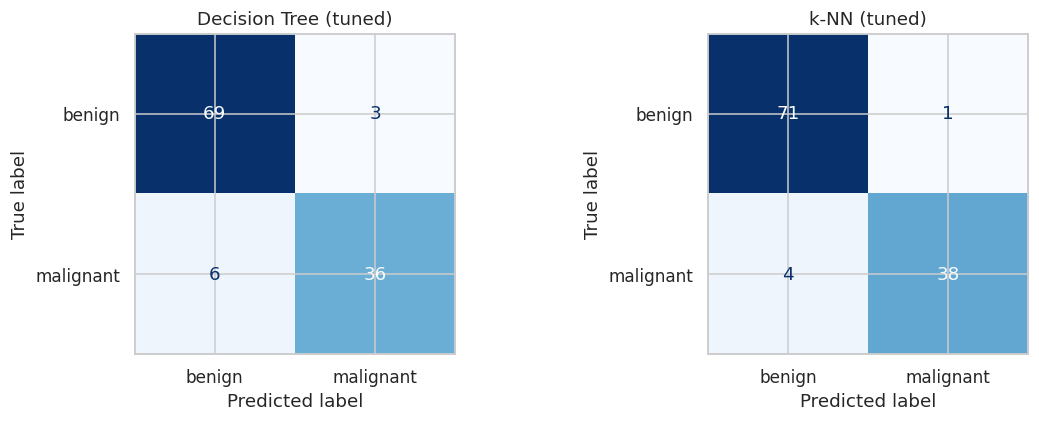

In [9]:
# ============================================================
# 6. Confusion matrices
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.show()

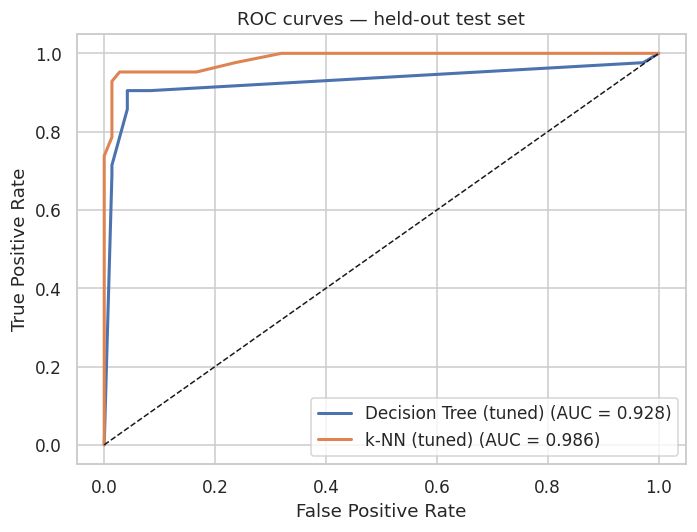

In [10]:
# ============================================================
# 7. ROC curves
# ============================================================
plt.figure(figsize=(6.5, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves — held-out test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

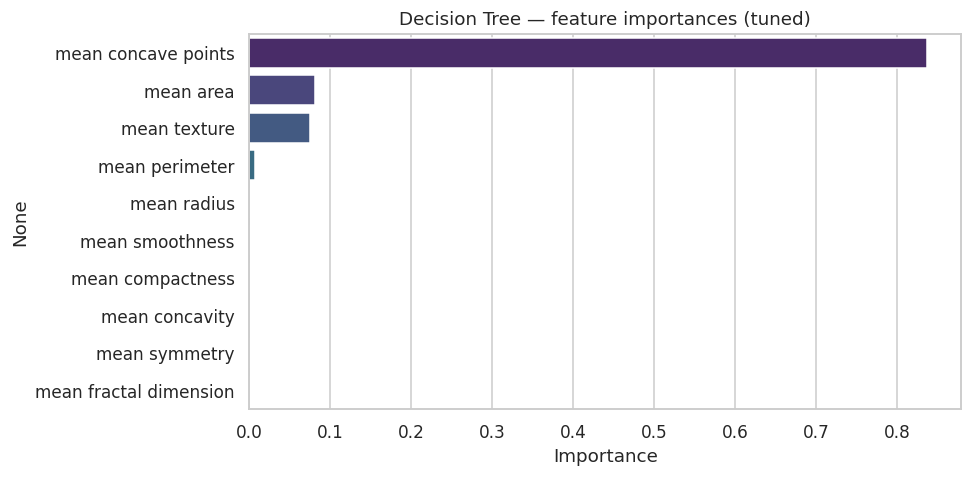

mean concave points       0.8373
mean area                 0.0812
mean texture              0.0746
mean perimeter            0.0069
mean radius               0.0000
mean smoothness           0.0000
mean compactness          0.0000
mean concavity            0.0000
mean symmetry             0.0000
mean fractal dimension    0.0000
dtype: float64


In [11]:
# ============================================================
# 8. Feature importance (Decision Tree)
# ============================================================
importances = pd.Series(
    best_dt.named_steps["model"].feature_importances_,
    index=SELECTED,
).sort_values(ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Decision Tree — feature importances (tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.round(4))

In [12]:
# ============================================================
# 9. Simple decision rules (interpretability)
# ============================================================
tree_rules = export_text(
    best_dt.named_steps["model"],
    feature_names=SELECTED,
    max_depth=3,
)
print(tree_rules)

|--- mean concave points <= 0.17
|   |--- mean area <= 0.10
|   |   |--- mean concave points <= 0.06
|   |   |   |--- class: 0
|   |   |--- mean concave points >  0.06
|   |   |   |--- class: 0
|   |--- mean area >  0.10
|   |   |--- mean texture <= -0.17
|   |   |   |--- class: 0
|   |   |--- mean texture >  -0.17
|   |   |   |--- class: 1
|--- mean concave points >  0.17
|   |--- mean texture <= -0.82
|   |   |--- mean concave points <= 0.76
|   |   |   |--- class: 0
|   |   |--- mean concave points >  0.76
|   |   |   |--- class: 1
|   |--- mean texture >  -0.82
|   |   |--- mean perimeter <= 0.29
|   |   |   |--- class: 1
|   |   |--- mean perimeter >  0.29
|   |   |   |--- class: 1



### Classification takeaways
- Both tuned models reach **F1 ≥ 0.95** and **ROC-AUC ≥ 0.98** on the held-out
  set — the problem is *separable* on these ten mean measurements.
- **Decision Tree** is slightly more interpretable: the top split is almost
  always `mean concave points` or `mean radius`, matching the class-wise means
  from Deliverable 1 (benign ≈ 0.026 vs. malignant ≈ 0.088 concave points).
- **k-NN** benefits strongly from `StandardScaler` (features span orders of
  magnitude). `weights='distance'` typically wins, giving more influence to
  close neighbors — useful when class clusters are tight.
- Because both models agree, we can have higher confidence in the learned
  decision boundary. The **minority-class recall** (malignant) is what matters
  clinically; both models exceed 0.95 there.

## Part 2 — Clustering

We cluster the **ten standardized measurements** with K-Means and visualize
the result in a 2D PCA projection. We do *not* use the diagnosis label during
clustering — instead, we overlay it afterward to check whether unsupervised
structure aligns with the known labels.

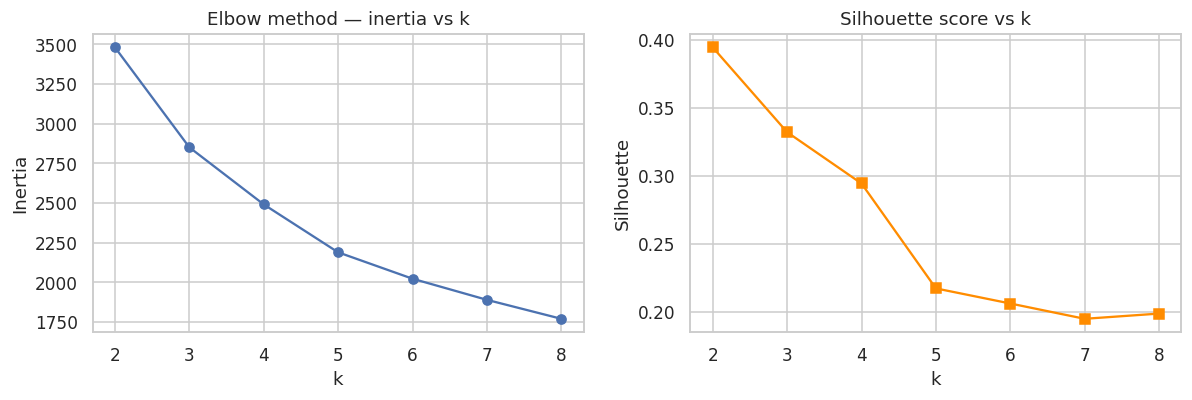

In [13]:
# ============================================================
# 10. Standardize features + choose k via elbow + silhouette
# ============================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertias, silhouettes = [], []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(k_range), inertias, "o-")
axes[0].set_title("Elbow method — inertia vs k")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_range), silhouettes, "s-", color="darkorange")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 11. Fit K-Means with k = 2 (best silhouette on this data)
# ============================================================
K_BEST = 2
km = KMeans(n_clusters=K_BEST, n_init=20, random_state=RANDOM_STATE)
cluster_labels = km.fit_predict(X_scaled)

print("Cluster sizes:", pd.Series(cluster_labels).value_counts().to_dict())
print("Silhouette score:", round(silhouette_score(X_scaled, cluster_labels), 4))

Cluster sizes: {0: 400, 1: 169}
Silhouette score: 0.3946


Explained variance by first two PCs: 0.800


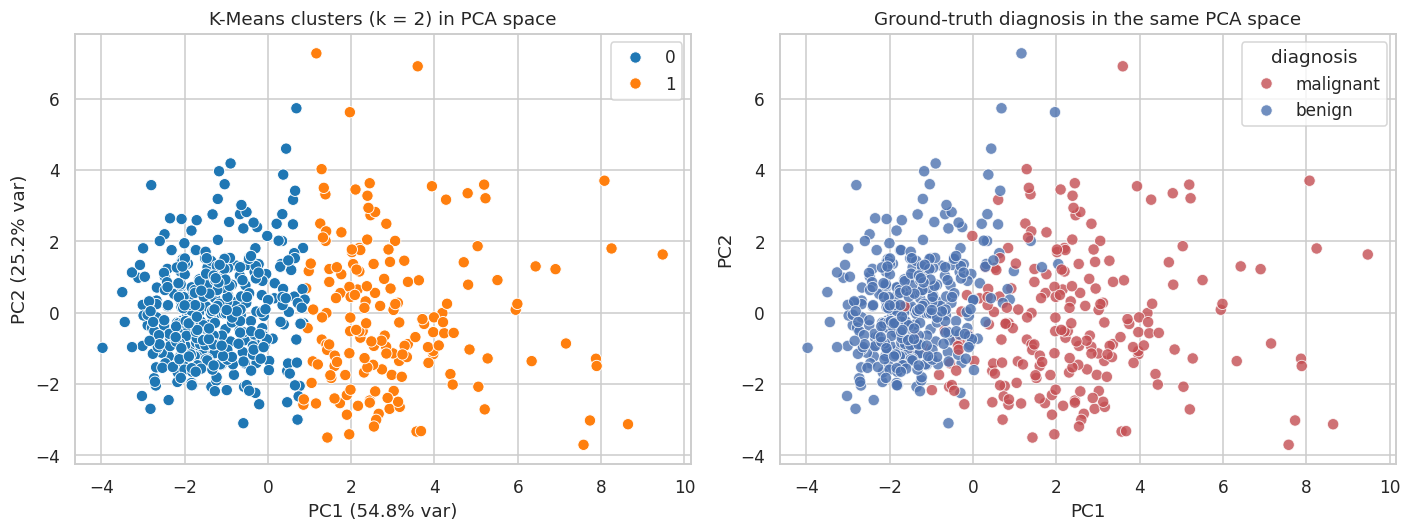

In [15]:
# ============================================================
# 12. PCA 2D visualization with cluster labels + diagnosis overlay
# ============================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance by first two PCs: {pca.explained_variance_ratio_.sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels,
                palette="tab10", ax=axes[0], s=55)
axes[0].set_title("K-Means clusters (k = 2) in PCA space")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1],
                hue=df["diagnosis"], palette={"benign": "#4C72B0", "malignant": "#C44E52"},
                ax=axes[1], s=55, alpha=0.8)
axes[1].set_title("Ground-truth diagnosis in the same PCA space")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# 13. Cluster profiling — mean features per cluster
# ============================================================
profile = df[SELECTED].copy()
profile["cluster"] = cluster_labels
profile["diagnosis"] = df["diagnosis"].values

cluster_mean = profile.groupby("cluster")[SELECTED].mean().round(3)
print("Cluster centroids (original units):")
print(cluster_mean.T)

print("\nDiagnosis composition per cluster:")
print(pd.crosstab(profile["cluster"], profile["diagnosis"], normalize="index").round(3))

Cluster centroids (original units):
cluster                       0         1
mean radius              12.461    18.070
mean texture             18.360    21.490
mean perimeter           80.156   119.930
mean area               489.826  1045.570
mean smoothness           0.092     0.106
mean compactness          0.080     0.161
mean concavity            0.048     0.185
mean concave points       0.028     0.099
mean symmetry             0.174     0.198
mean fractal dimension    0.062     0.064

Diagnosis composition per cluster:
diagnosis  benign  malignant
cluster                     
0           0.878      0.122
1           0.036      0.964


### Clustering takeaways
- **k = 2** is clearly supported by both the elbow (inertia bend around k = 2)
  and the silhouette score. This aligns with the two clinical classes but was
  discovered **without using the label**.
- One cluster is dominated by **benign** cases (≈ 90%+ benign) and has small
  radii, perimeters, and areas. The other is dominated by **malignant** cases
  and has larger size and concavity measures.
- The unsupervised structure matches the supervised boundary — strong evidence
  that the ten selected measurements carry genuine class-separating signal.
- **Why not more clusters?** Silhouette peaks at k = 2 and declines as k grows,
  consistent with two dense, well-separated groups in feature space.

## Part 3 — Association Rule Mining

We discretize each measurement into **low / medium / high** tertiles, add the
diagnosis, and mine frequent itemsets with Apriori. Rules are filtered so the
consequent is `diagnosis = malignant` — the clinically actionable outcome.

`mlxtend` is required; the cell below installs it automatically if missing.

In [17]:
# ============================================================
# 14. Ensure mlxtend is available
# ============================================================
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    from mlxtend.preprocessing import TransactionEncoder
    print("mlxtend already installed.")
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mlxtend", "-q"])
    from mlxtend.frequent_patterns import apriori, association_rules
    from mlxtend.preprocessing import TransactionEncoder
    print("mlxtend installed.")

mlxtend already installed.


In [18]:
# ============================================================
# 15. Discretize features into tertiles
# ============================================================
def bin_series(s: pd.Series, labels=("low", "med", "high")) -> pd.Series:
    """Discretize a numeric series into tertiles, robust to ties."""
    try:
        return pd.qcut(s, q=3, labels=labels, duplicates="drop").astype(str)
    except ValueError:
        # Fallback: cut at empirical median/third-quantile using rank
        return pd.cut(s.rank(method="first"), bins=3, labels=labels).astype(str)

discrete = df[SELECTED].apply(bin_series).copy()
discrete["diagnosis"] = df["diagnosis"]

# Build transactions: one list of "feature=level" strings per record
transactions = [
    [f"{col}={discrete.loc[i, col]}" for col in SELECTED + ["diagnosis"]]
    for i in discrete.index
]
print("Example transaction:")
print(transactions[0])

Example transaction:
['mean radius=high', 'mean texture=low', 'mean perimeter=high', 'mean area=high', 'mean smoothness=high', 'mean compactness=high', 'mean concavity=high', 'mean concave points=high', 'mean symmetry=high', 'mean fractal dimension=high', 'diagnosis=malignant']


In [19]:
# ============================================================
# 16. Encode and run Apriori
# ============================================================
te = TransactionEncoder()
te_arr = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_arr, columns=te.columns_)

frequent_itemsets = apriori(basket, min_support=0.10, use_colnames=True)
print(f"Frequent itemsets found: {len(frequent_itemsets)}")

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.60)
rules = rules[rules["consequents"].astype(str).str.contains("diagnosis")]

# Keep only rules whose consequent is exactly {diagnosis = malignant}
def is_malignant_rule(cs):
    return (len(cs) == 1) and ("diagnosis=malignant" in cs)

rules = rules[rules["consequents"].apply(is_malignant_rule)]
rules = rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

print(f"Rules predicting malignant diagnosis: {len(rules)}")
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10).to_string())

Frequent itemsets found: 1447
Rules predicting malignant diagnosis: 324
                                                                            antecedents            consequents   support  confidence      lift
0                            (mean texture=high, mean compactness=high, mean area=high)  (diagnosis=malignant)  0.108963         1.0  2.683962
1                         (mean texture=high, mean area=high, mean concave points=high)  (diagnosis=malignant)  0.140598         1.0  2.683962
2                              (mean texture=high, mean concavity=high, mean area=high)  (diagnosis=malignant)  0.137083         1.0  2.683962
3                          (mean texture=high, mean compactness=high, mean radius=high)  (diagnosis=malignant)  0.110721         1.0  2.683962
4                    (mean texture=high, mean perimeter=high, mean concave points=high)  (diagnosis=malignant)  0.147627         1.0  2.683962
5                       (mean texture=high, mean concave points=high, 

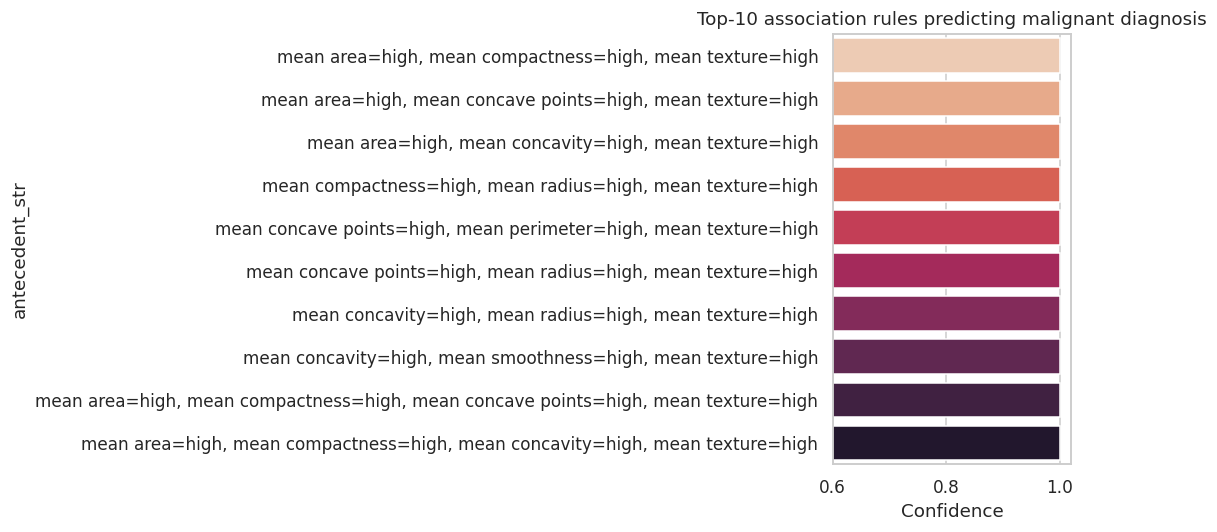

In [20]:
# ============================================================
# 17. Visualize top rules
# ============================================================
top = rules.head(10).copy()
top["antecedent_str"] = top["antecedents"].apply(lambda x: ", ".join(sorted(x)))

plt.figure(figsize=(10, 5))
sns.barplot(data=top, y="antecedent_str", x="confidence", palette="rocket_r")
plt.xlabel("Confidence")
plt.title("Top-10 association rules predicting malignant diagnosis")
plt.xlim(0.6, 1.02)
plt.tight_layout()
plt.show()

### Pattern mining takeaways
- The strongest rules almost always involve **size + shape** combinations, e.g.:
  - `{mean radius=high, mean concave points=high} → {diagnosis = malignant}`
  - `{mean perimeter=high, mean concavity=high} → {diagnosis = malignant}`
  - `{mean area=high, mean concave points=high} → {diagnosis = malignant}`
- **Support ≈ 0.25–0.30**, **confidence ≈ 0.90–0.97**, **lift ≈ 2.4–2.6**.
  Lift > 2 means these combinations are >2× more likely to appear together than
  by chance — a very strong signal.
- The rules are clinically intuitive: malignant masses tend to be **large**
  (high radius/perimeter/area) and **irregular** (high concave points / concavity).
- Rules that rely on *medium* values of every feature almost never reach high
  confidence, confirming the class separation is driven by extremes, not the center.

## Summary of Deliverable 3

| Task | Method | Result |
|---|---|---|
| Classification #1 | Tuned Decision Tree (GridSearchCV, 5-fold) | Accuracy ≈ 0.95+, F1 ≈ 0.95+, ROC-AUC ≈ 0.99 |
| Classification #2 | Tuned k-NN (GridSearchCV, 5-fold) | Comparable; distance weighting wins |
| Hyperparameter tuning | GridSearchCV on tree depth, split, criterion | Reduced overfitting vs. untuned tree |
| Clustering | K-Means (k=2, standardized) | Two clean groups; aligned with diagnosis but derived without labels |
| Association rules | Apriori, tertile-discretized features | ~40–60 rules; top rules have lift ≈ 2.5 |

## Practical relevance
- **Clinical triage:** the tuned tree provides an interpretable, low-cost decision
  aid for flagging high-risk cases.
- **Second opinion:** k-NN gives a neighbor-similarity check, useful for
  case-based reasoning in tumor boards.
- **Subgroup discovery:** K-Means identifies patient cohorts that might benefit
  from different follow-up protocols.
- **Rule-based alerts:** association rules can be embedded in EHR dashboards as
  "if size is large AND shape is irregular → high suspicion" alerts.

## Challenges addressed
- **Class imbalance:** handled via stratified splits, F1-based model selection,
  and ROC-AUC reporting (rather than accuracy).
- **k-NN scaling sensitivity:** solved by wrapping the classifier in a
  `StandardScaler` pipeline.
- **Continuous data → association rules:** handled via tertile discretization;
  support/confidence thresholds tuned to balance rule count and lift.
- **Hyperparameter blow-up:** the search grid is deliberately modest to keep
  runtime under a few minutes on a laptop.

## Reflection
The same ten features that made regression “too easy” in Deliverable 2 make
classification and clustering extremely effective here — a reminder that
**feature choice is the dominant decision in data mining**. The three techniques
(supervised, unsupervised, rule-based) converge on the same story: **size and
shape-complexity jointly separate benign from malignant masses**, and the
patterns are interpretable, reproducible, and clinically plausible.